# Stats 161 Midterm Project

## Data import

We select **12 consecutive weeks of Polymarket data, from June 1 to August 23, 2026**, to study wallet trading behavior. All dates and timestamps use UTC.


### 1. Setup


In [1]:
import pandas as pd
import requests

from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from io import BytesIO


### 2. Dates and access settings


In [2]:
start_date = "2026-06-01"
end_date = "2026-08-23"
dates = pd.date_range(start_date, end_date, freq="D", tz="UTC")

base_url = "https://d1yyqbluk0oz0t.cloudfront.net"
course_password = 'PolymarketData2026!'


### 3. Wallet trades

We combine the 84 daily trade files into `wallet_trades`, keeping all wallets and all eight original variables. Each row is a recorded fill; one order may produce multiple fills.

| Variable | Description |
|---|---|
| `wallet` | Pseudonymous wallet ID, consistent across daily files. |
| `market` | Market slug; links to `markets.slug`. |
| `time` | Fill timestamp in UTC. |
| `side` | BUY or SELL for the recorded wallet. |
| `outcome` | Traded outcome, such as Yes, No, Up, Down, or a team name. |
| `price` | Execution price per share. |
| `size` | Number of shares traded. |
| `dollars` | Recorded dollar value of the fill. |


In [3]:
session = requests.Session()
session.auth = ("polymarketdatabase", course_password)
daily_trades = []

for day in dates:
    date_string = day.strftime("%Y-%m-%d")
    url = f"{base_url}/wallet_trades/trades-{date_string}.parquet"

    response = session.get(url, timeout=120)
    response.raise_for_status()
    day_trades = pd.read_parquet(BytesIO(response.content), dtype_backend="pyarrow")
    day_trades["time"] = pd.to_datetime(day_trades["time"], utc=True)

    # Check the file date.
    assert len(day_trades) > 0, f"Empty file: {date_string}"
    assert day_trades["time"].min().date() == day.date(), f"Unexpected date: {date_string}"
    assert day_trades["time"].max().date() == day.date(), f"Unexpected date: {date_string}"

    daily_trades.append(day_trades)
    if len(daily_trades) % 28 == 0:
        print(f"Loaded {len(daily_trades)} of {len(dates)} daily files.")

wallet_trades = pd.concat(daily_trades, ignore_index=True)
session.close()
del daily_trades, day_trades, response

print(f"Wallet trades imported: {len(wallet_trades):,} rows.")


Loaded 28 of 84 daily files.
Loaded 56 of 84 daily files.
Loaded 84 of 84 daily files.
Wallet trades imported: 66,736,398 rows.


### 4. Related market data

We import market, event, and settlement records for the markets in `wallet_trades`. All original columns are retained; key variables are listed below.

| DataFrame | Content | Key variables |
|---|---|---|
| `markets` | Market questions, outcome labels, and parent events. | `slug`, `title`, `event_slug`, `condition_id`, `outcomes`, `token_ids`, `start_date`, `end_date` |
| `events` | Event titles, descriptions, and scheduled dates. | `slug`, `title`, `description`, `start_date`, `end_date` |
| `resolutions` | Available settlement records. | `market_slug`, `resolved_yes`, `price_at_close`, `resolved_at` |

**Links:** `wallet_trades.market` → `markets.slug`; `markets.event_slug` → `events.slug`; `resolutions.market_slug` → `markets.slug`.

Market prices and volumes in the metadata reflect the current stored snapshot. Interpret resolution labels using the market's actual outcome labels.


In [4]:
database_url = URL.create(
    "postgresql+psycopg2",
    username="polymarketdatabase.merbqatlxbrcvtbnuaqe",
    password=course_password,
    host="aws-0-us-west-2.pooler.supabase.com",
    port=6543,
    database="postgres",
)

engine = create_engine(
    database_url,
    connect_args={"sslmode": "require", "connect_timeout": 20},
    execution_options={"postgresql_readonly": True},
)

market_slugs = wallet_trades["market"].dropna().unique().tolist()

with engine.connect() as connection:
    markets = pd.read_sql_query(
        text("SELECT * FROM public.markets WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )
    resolutions = pd.read_sql_query(
        text("SELECT * FROM public.resolutions WHERE market_slug = ANY(:slugs)"),
        connection,
        params={"slugs": market_slugs},
    )


In [5]:
event_slugs = markets["event_slug"].dropna().unique().tolist()

with engine.connect() as connection:
    events = pd.read_sql_query(
        text("SELECT * FROM public.events WHERE slug = ANY(:slugs)"),
        connection,
        params={"slugs": event_slugs},
    )

engine.dispose()


### 5. Import check

Confirm the row and column counts, and report traded markets without matching catalog metadata.


In [6]:
for name, data in [("wallet_trades", wallet_trades), ("markets", markets),
                   ("events", events), ("resolutions", resolutions)]:
    print(f"{name}: {len(data):,} rows, {len(data.columns)} columns")

missing_market_slugs = set(market_slugs) - set(markets["slug"])
print(f"Traded market slugs without catalog metadata: {len(missing_market_slugs):,}")
print(f"Study period: {start_date} through {end_date} (UTC)")


wallet_trades: 66,736,398 rows, 8 columns
markets: 227,655 rows, 25 columns
events: 98,132 rows, 13 columns
resolutions: 42,877 rows, 6 columns
Traded market slugs without catalog metadata: 119
Study period: 2026-06-01 through 2026-08-23 (UTC)


## Data Cleaning

### 1. Check data quality

Check missing values, trade fields, recorded amounts (tolerance: $0.01), repeated rows, and market links. Counts can overlap.


In [7]:
missing_values = wallet_trades.isna().any(axis=1)
invalid_side = ~wallet_trades["side"].isin(["BUY", "SELL"])
invalid_price = ~wallet_trades["price"].between(0, 1)
negative_size = wallet_trades["size"] < 0
negative_dollars = wallet_trades["dollars"] < 0
amount_mismatch = (
    wallet_trades["dollars"] - wallet_trades["price"] * wallet_trades["size"]
).abs() > 0.01
repeated_rows = wallet_trades.duplicated()
missing_metadata = ~wallet_trades["market"].isin(markets["slug"])

quality_check = pd.Series({
    "Missing values in any trade column": missing_values.sum(),
    "Side outside BUY / SELL": invalid_side.sum(),
    "Price outside [0, 1]": invalid_price.sum(),
    "Negative shares": negative_size.sum(),
    "Negative dollar value": negative_dollars.sum(),
    "Dollar difference above $0.01": amount_mismatch.sum(),
    "Repeated rows after the first": repeated_rows.sum(),
    "Trades without market metadata": missing_metadata.sum(),
}, name="Rows").to_frame()

quality_check


,Rows
Missing values in any trade column,0
Side outside BUY / SELL,0
"Price outside [0, 1]",0
Negative shares,0
Negative dollar value,0
Dollar difference above $0.01,0
Repeated rows after the first,2509300
Trades without market metadata,147668


### 2. Prepare the analysis data

Use `clean_trades` for the next analysis steps.

The checks found no missing or invalid trade values, so no rows need to be removed.

Repeated rows are kept because identical records cannot be confirmed as duplicates without a trade ID. Trades without market metadata are also kept. `has_market_metadata` indicates whether a trade's `market` matches `markets.slug`.

Large trades and low-activity wallets are retained.


In [8]:
clean_trades = wallet_trades.copy()
clean_trades["has_market_metadata"] = ~missing_metadata

print(f"Rows retained: {len(clean_trades):,}")
print(f"Rows removed: {len(wallet_trades) - len(clean_trades):,}")


Rows retained: 66,736,398
Rows removed: 0


## Wallet Features

Each row in `wallet_features` describes one wallet during a four-week period.

| Period | UTC dates |
|---|---|
| 1 | June 1–June 28, 2026 |
| 2 | June 29–July 26, 2026 |
| 3 | July 27–August 23, 2026 |

| Candidate feature | Definition |
|---|---|
| `active_days` | Number of days with at least one fill. |
| `fills_per_active_day` | Fill count divided by active days. |
| `median_fill_dollars` | Median recorded dollar value per fill. |
| `n_markets` | Number of distinct markets traded. |
| `top_market_share` | Largest market's share of recorded dollars; undefined if total dollars are zero. |
| `buy_fill_share` | BUY fills divided by all fills. |
| `buy_sell_market_share` | Share of traded markets with both BUY and SELL fills for at least one common outcome. |
| `busiest_day_share` | Busiest day's fill count divided by all fills. |
| `median_buy_price` | Median execution price among BUY fills; missing when there are no BUY fills. |

`wallet` and `period` identify each row. `n_fills` and `total_dollars` are supporting measures.


### 1. Four-week periods


In [9]:
feature_trades = clean_trades.copy()
feature_trades["day"] = feature_trades["time"].dt.floor("D")
feature_trades["period"] = (
    (feature_trades["day"] - pd.Timestamp(start_date, tz="UTC")).dt.days // 28 + 1
)
feature_trades["is_buy"] = feature_trades["side"] == "BUY"

group_keys = ["wallet", "period"]


### 2. Basic wallet activity


In [10]:
wallet_features = feature_trades.groupby(group_keys).agg(
    n_fills=("wallet", "size"),
    total_dollars=("dollars", "sum"),
    active_days=("day", "nunique"),
    median_fill_dollars=("dollars", "median"),
    n_markets=("market", "nunique"),
)

wallet_features["fills_per_active_day"] = (
    wallet_features["n_fills"] / wallet_features["active_days"]
)


### 3. Concentration across markets and days


In [11]:
market_dollars = feature_trades.groupby(group_keys + ["market"])["dollars"].sum()
top_market_dollars = market_dollars.groupby(level=group_keys).max()
wallet_features["top_market_share"] = (
    top_market_dollars
    / wallet_features["total_dollars"].where(wallet_features["total_dollars"] > 0)
)

daily_fills = feature_trades.groupby(group_keys + ["day"]).size()
wallet_features["busiest_day_share"] = (
    daily_fills.groupby(level=group_keys).max() / wallet_features["n_fills"]
)


### 4. Buying and selling


In [12]:
wallet_features["buy_fill_share"] = feature_trades.groupby(group_keys)["is_buy"].mean()
feature_trades["buy_price"] = feature_trades["price"].where(feature_trades["is_buy"])
wallet_features["median_buy_price"] = (
    feature_trades.groupby(group_keys)["buy_price"].median()
)

outcome_sides = feature_trades.groupby(
    group_keys + ["market", "outcome"]
)["side"].nunique()
market_has_buy_sell = outcome_sides.eq(2).groupby(
    level=group_keys + ["market"]
).any()
wallet_features["buy_sell_market_share"] = (
    market_has_buy_sell.groupby(level=group_keys).sum() / wallet_features["n_markets"]
)


### 5. Wallet feature table

Keep every wallet-period with observed trades. A wallet with no trades in a period has no row for that period. Activity thresholds, scaling, and model selection come later.


In [13]:
feature_columns = [
    "active_days", "fills_per_active_day", "median_fill_dollars",
    "n_markets", "top_market_share", "buy_fill_share",
    "buy_sell_market_share", "busiest_day_share", "median_buy_price",
]
wallet_features = wallet_features.reset_index()[
    ["wallet", "period"] + feature_columns + ["n_fills", "total_dollars"]
]

print(f"Wallet-period rows: {len(wallet_features):,}")
print(f"Distinct wallets: {wallet_features['wallet'].nunique():,}")
print(f"Missing BUY-price medians: {wallet_features['median_buy_price'].isna().sum():,}")
wallet_features.head(6)


Wallet-period rows: 1,154,562
Distinct wallets: 779,519
Missing BUY-price medians: 67,918


,wallet,period,active_days,fills_per_active_day,median_fill_dollars,n_markets,top_market_share,buy_fill_share,buy_sell_market_share,busiest_day_share,median_buy_price,n_fills,total_dollars
0,0x000025e0e96474e2485e259558e53f2dd4a54626,1,4,12.0,42.349999,35,0.099013,0.729167,0.371429,0.395833,0.52,48,2188.836554
1,0x000028713780b8882e3f11559f9c173802b3d716,1,14,33.5,16.6907,223,0.033329,0.703625,0.578475,0.204691,0.33,469,10510.332006
2,0x000028713780b8882e3f11559f9c173802b3d716,2,1,2.0,6.999999,2,0.5,1.0,0.000000,1.0,0.152886,2,13.999999
3,0x0000381a4e54c779318b9005f6c637cafb631e62,1,22,2.272727,56.43,31,0.087263,0.7,0.451613,0.1,0.54,50,2735.1852
4,0x00006123754dc778ea3abdd86e71a5d6d8fbd5b1,2,1,1.0,37.229999,1,1.0,1.0,0.000000,1.0,0.41,1,37.229999
5,0x000096d4e7bfabe3e83b61bca461a83d082295df,1,2,1.0,1.7675,2,0.603961,1.0,0.000000,0.5,0.4485,2,3.534999


## Market Activity

Use daily trading activity to explore when markets become more active. `active_wallets` is our main measure; fills and recorded dollars provide context.

### 1. Daily market activity

Each row in `market_daily` is one market on one UTC day with recorded fills.

| Variable | Definition |
|---|---|
| `market` | Market slug. |
| `day` | UTC date. |
| `active_wallets` | Number of distinct wallets with at least one fill that day. |
| `n_fills` | Number of recorded fills that day. |
| `total_dollars` | Sum of recorded fill dollars that day. |

Dates with no fills are omitted from this table and filled with zero when plotting.


In [14]:
market_daily = feature_trades.groupby(["market", "day"], as_index=False).agg(
    active_wallets=("wallet", "nunique"),
    n_fills=("wallet", "size"),
    total_dollars=("dollars", "sum"),
)

print(f"Market-day rows with fills: {len(market_daily):,}")
market_daily.head()


Market-day rows with fills: 830,738


,market,day,active_wallets,n_fills,total_dollars
0,0-ships-transit-hormuz-on-any-date-by-august-31,2026-07-29 00:00:00+00:00,4,4,130.203196
1,0-ships-transit-hormuz-on-any-date-by-august-31,2026-07-31 00:00:00+00:00,1,1,10.0
2,0-ships-transit-hormuz-on-any-date-by-august-31,2026-08-01 00:00:00+00:00,2,2,3.25
3,0-ships-transit-hormuz-on-any-date-by-august-31,2026-08-02 00:00:00+00:00,2,2,930.9907
4,0-ships-transit-hormuz-on-any-date-by-august-31,2026-08-03 00:00:00+00:00,5,14,3995.381436


### 2. Trading coverage

Count how many markets have trading records across multiple days. `active_days` counts days with fills. The first and last observed trade days describe our sample, not a market's launch or closing date.


In [15]:
market_summary = market_daily.groupby("market").agg(
    active_days=("day", "size"),
    first_trade_day=("day", "min"),
    last_trade_day=("day", "max"),
    peak_wallets=("active_wallets", "max"),
)
market_summary = market_summary.join(markets.set_index("slug")["title"])

market_coverage = pd.Series({
    "Markets with recorded fills": len(market_summary),
    "Markets with at least 7 active days": (market_summary["active_days"] >= 7).sum(),
    "Markets with at least 14 active days": (market_summary["active_days"] >= 14).sum(),
    "Markets with at least 28 active days": (market_summary["active_days"] >= 28).sum(),
    "Markets active on all 84 days": (market_summary["active_days"] == len(dates)).sum(),
}, name="Markets").to_frame()

market_coverage


,Markets
Markets with recorded fills,227774
Markets with at least 7 active days,23815
Markets with at least 14 active days,12620
Markets with at least 28 active days,5192
Markets active on all 84 days,338


### 3. Example activity curves

For a first visual check, select the three largest daily wallet peaks among markets with at least 28 active days. This selection is only for illustration; it does not define our final sample or a surge threshold.


In [16]:
example_markets = market_summary.loc[
    market_summary["active_days"] >= 28
].nlargest(3, "peak_wallets")

example_markets[["title", "active_days", "first_trade_day", "last_trade_day", "peak_wallets"]]


,title,active_days,first_trade_day,last_trade_day,peak_wallets
market,,,,,
will-argentina-win-the-2026-fifa-world-cup-245,Will Argentina win the 2026 FIFA World Cup?,50,2026-06-01 00:00:00+00:00,2026-07-20 00:00:00+00:00,10834
will-spain-win-the-2026-fifa-world-cup-963,Will Spain win the 2026 FIFA World Cup?,50,2026-06-01 00:00:00+00:00,2026-07-20 00:00:00+00:00,9750
fifwc-col-prt-2026-06-27-prt,Will Portugal win on 2026-06-27?,28,2026-06-01 00:00:00+00:00,2026-06-28 00:00:00+00:00,8392


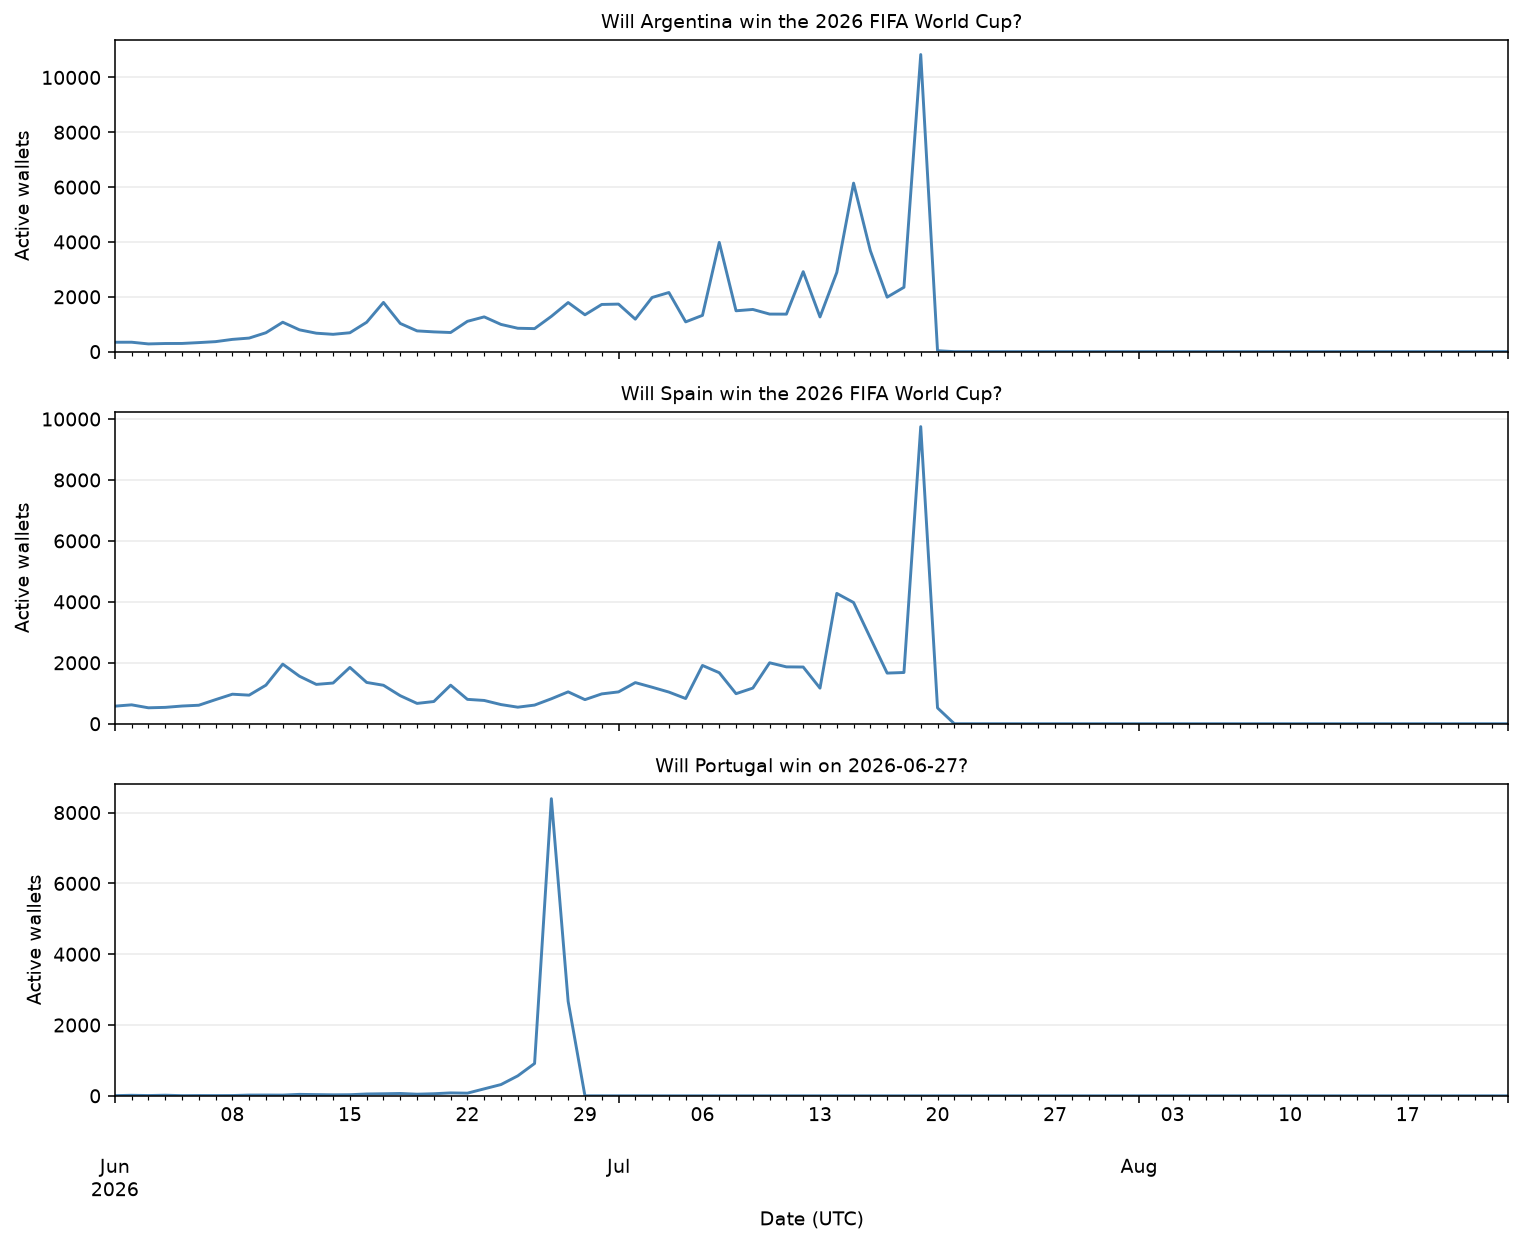

In [17]:
import matplotlib.pyplot as plt
from textwrap import fill

fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

for ax, market in zip(axes, example_markets.index):
    daily_wallets = market_daily.loc[
        market_daily["market"] == market
    ].set_index("day")["active_wallets"].reindex(dates, fill_value=0)
    daily_wallets.plot(ax=ax, color="steelblue")
    title = example_markets.loc[market, "title"]
    ax.set_title(fill(title if pd.notna(title) else market, 75), fontsize=10)
    ax.set_ylabel("Active wallets")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)

axes[-1].set_xlabel("Date (UTC)")
fig.tight_layout()
plt.show()


These examples are sports markets. Their peaks may reflect scheduled matches or the approach of a market ending. When defining surge events, account for the market lifecycle and allow enough time to observe participation before and after the surge.


## Market Surge Events

Identify candidate surges before comparing wallet profiles. Our initial rule requires **at least 50 active wallets** and **at least 3 times the previous seven-day mean**. The baseline must be positive. Consecutive qualifying days count as one event, dated at the start of the run.

Use period 2 or 3 for events and the preceding four-week period for wallet profiles. Each event needs seven days before and after it within the same observation period.

### 1. Check market dates

Use the earlier of the stored scheduled end and resolution time as a conservative cutoff. These fields do not establish the exact time trading stopped. Markets without either date are excluded from the candidate sample. This screening does not require wallets to keep trading after a surge.


In [18]:
market_dates = markets.set_index("slug")[["title", "end_date"]].rename(
    columns={"end_date": "scheduled_end"}
)
market_dates["resolved_at"] = resolutions.set_index("market_slug")["resolved_at"]
market_dates["market_end"] = market_dates[["scheduled_end", "resolved_at"]].min(axis=1)
market_dates = market_dates.join(
    market_summary[["first_trade_day", "last_trade_day", "peak_wallets"]]
)

date_check = pd.Series({
    "Traded markets": len(market_summary),
    "Traded markets without an end cutoff": len(market_summary) - market_dates["market_end"].notna().sum(),
    "Markets with fills after scheduled end day": (
        market_dates["last_trade_day"] > market_dates["scheduled_end"].dt.floor("D")
    ).sum(),
    "Markets with fills after resolution day": (
        market_dates["last_trade_day"] > market_dates["resolved_at"].dt.floor("D")
    ).sum(),
}, name="Markets").to_frame()

date_check


,Markets
Traded markets,227774
Traded markets without an end cutoff,2659
Markets with fills after scheduled end day,17309
Markets with fills after resolution day,10


### 2. Daily baseline

Check markets that can meet the 50-wallet minimum and have enough calendar time for a 15-day window. Fill dates with no trades with zero. Shift the daily counts before calculating the rolling mean so the baseline excludes the current day.


In [19]:
min_wallets = 50
min_growth = 3
window_days = 7

markets_to_check = market_dates.loc[
    (market_dates["peak_wallets"] >= min_wallets)
    & (market_dates["market_end"] >= market_dates["first_trade_day"]
       + pd.Timedelta(days=2 * window_days + 1))
].index
calendar = pd.MultiIndex.from_product([markets_to_check, dates], names=["market", "day"])
surge_activity = (
    market_daily.set_index(["market", "day"])[["active_wallets"]]
    .reindex(calendar, fill_value=0).reset_index()
)
previous_wallets = surge_activity.groupby("market")["active_wallets"].shift(1)
surge_activity["baseline_wallets"] = (
    previous_wallets.groupby(surge_activity["market"]).rolling(window_days).mean()
    .reset_index(level=0, drop=True)
)
surge_activity["growth_ratio"] = (
    surge_activity["active_wallets"]
    / surge_activity["baseline_wallets"].where(surge_activity["baseline_wallets"] > 0)
)


### 3. Candidate events

The observation windows allow surge dates of **July 6–19** in period 2 and **August 3–16** in period 3. Require a full seven-day history and a cutoff after the end of the seventh following day. Inspect activity and growth before applying the surge thresholds.


In [20]:
surge_activity = surge_activity.join(
    market_dates[["title", "first_trade_day", "market_end"]], on="market"
)
day_number = (surge_activity["day"] - dates[0]).dt.days
surge_activity["period"] = day_number // 28 + 1
in_observation_window = (
    (surge_activity["period"] >= 2)
    & (day_number % 28).between(window_days, 27 - window_days)
)
has_history = (
    surge_activity["first_trade_day"] <= surge_activity["day"] - pd.Timedelta(days=window_days)
)
has_followup = (
    surge_activity["market_end"] >= surge_activity["day"] + pd.Timedelta(days=window_days + 1)
)
can_observe = in_observation_window & has_history & has_followup

surge_activity.loc[
    can_observe, ["active_wallets", "baseline_wallets", "growth_ratio"]
].describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(2)


,active_wallets,baseline_wallets,growth_ratio
count,30290.00,30290.00,27108.00
mean,21.06,22.68,1.30
std,62.19,52.51,10.36
min,0.00,0.00,0.00
50%,7.00,10.00,0.78
90%,55.00,58.57,2.01
95%,92.00,93.71,3.15
99%,172.00,152.76,8.75
max,3984.00,2228.29,1449.00


In [21]:
surge_activity["is_surge"] = (
    (surge_activity["active_wallets"] >= min_wallets)
    & (surge_activity["growth_ratio"] >= min_growth)
)
previous_surge = surge_activity.groupby("market")["is_surge"].shift(1, fill_value=False)
surge_start = surge_activity["is_surge"] & ~previous_surge

surge_events = surge_activity.loc[
    surge_start & can_observe,
    ["market", "title", "period", "day", "active_wallets", "baseline_wallets",
     "growth_ratio", "market_end"],
].rename(columns={"day": "surge_day"}).reset_index(drop=True)

print(f"Candidate events: {len(surge_events):,}")
print(f"Distinct markets: {surge_events['market'].nunique():,}")
surge_events.groupby("period").agg(
    events=("market", "size"), markets=("market", "nunique")
).reindex([2, 3], fill_value=0)


Candidate events: 299
Distinct markets: 274


,events,markets
period,,
2,174,164
3,125,116


In [22]:
surge_events[[
    "title", "surge_day", "active_wallets", "baseline_wallets", "growth_ratio"
]].head(8).round({"baseline_wallets": 2, "growth_ratio": 2})


,title,surge_day,active_wallets,baseline_wallets,growth_ratio
0,Will Alexandria Ocasio-Cortez win the 2028 Dem...,2026-08-12 00:00:00+00:00,75,19.43,3.86
1,Will Alexandria Ocasio-Cortez win the 2028 Dem...,2026-08-14 00:00:00+00:00,91,30.00,3.03
2,Will the Athletics win the 2026 World Series?,2026-07-08 00:00:00+00:00,62,14.14,4.38
3,"Will BNB reach $1,000 in August?",2026-08-16 00:00:00+00:00,73,20.57,3.55
4,Iran leadership change by December 31?,2026-08-07 00:00:00+00:00,88,27.14,3.24
5,Will the Republicans win the Michigan Senate r...,2026-08-05 00:00:00+00:00,73,10.71,6.81
6,Will the Democrats win the Michigan Senate rac...,2026-08-05 00:00:00+00:00,68,11.57,5.88
7,Kash Patel out by December 31?,2026-07-11 00:00:00+00:00,129,6.43,20.07


### 4. Example events

Plot the three candidates with the highest wallet count on the surge day. Day 0 is the first qualifying day; the dotted line is the previous seven-day mean. These are illustrations of the initial rule. Separate runs in the same market may still have overlapping observation windows.


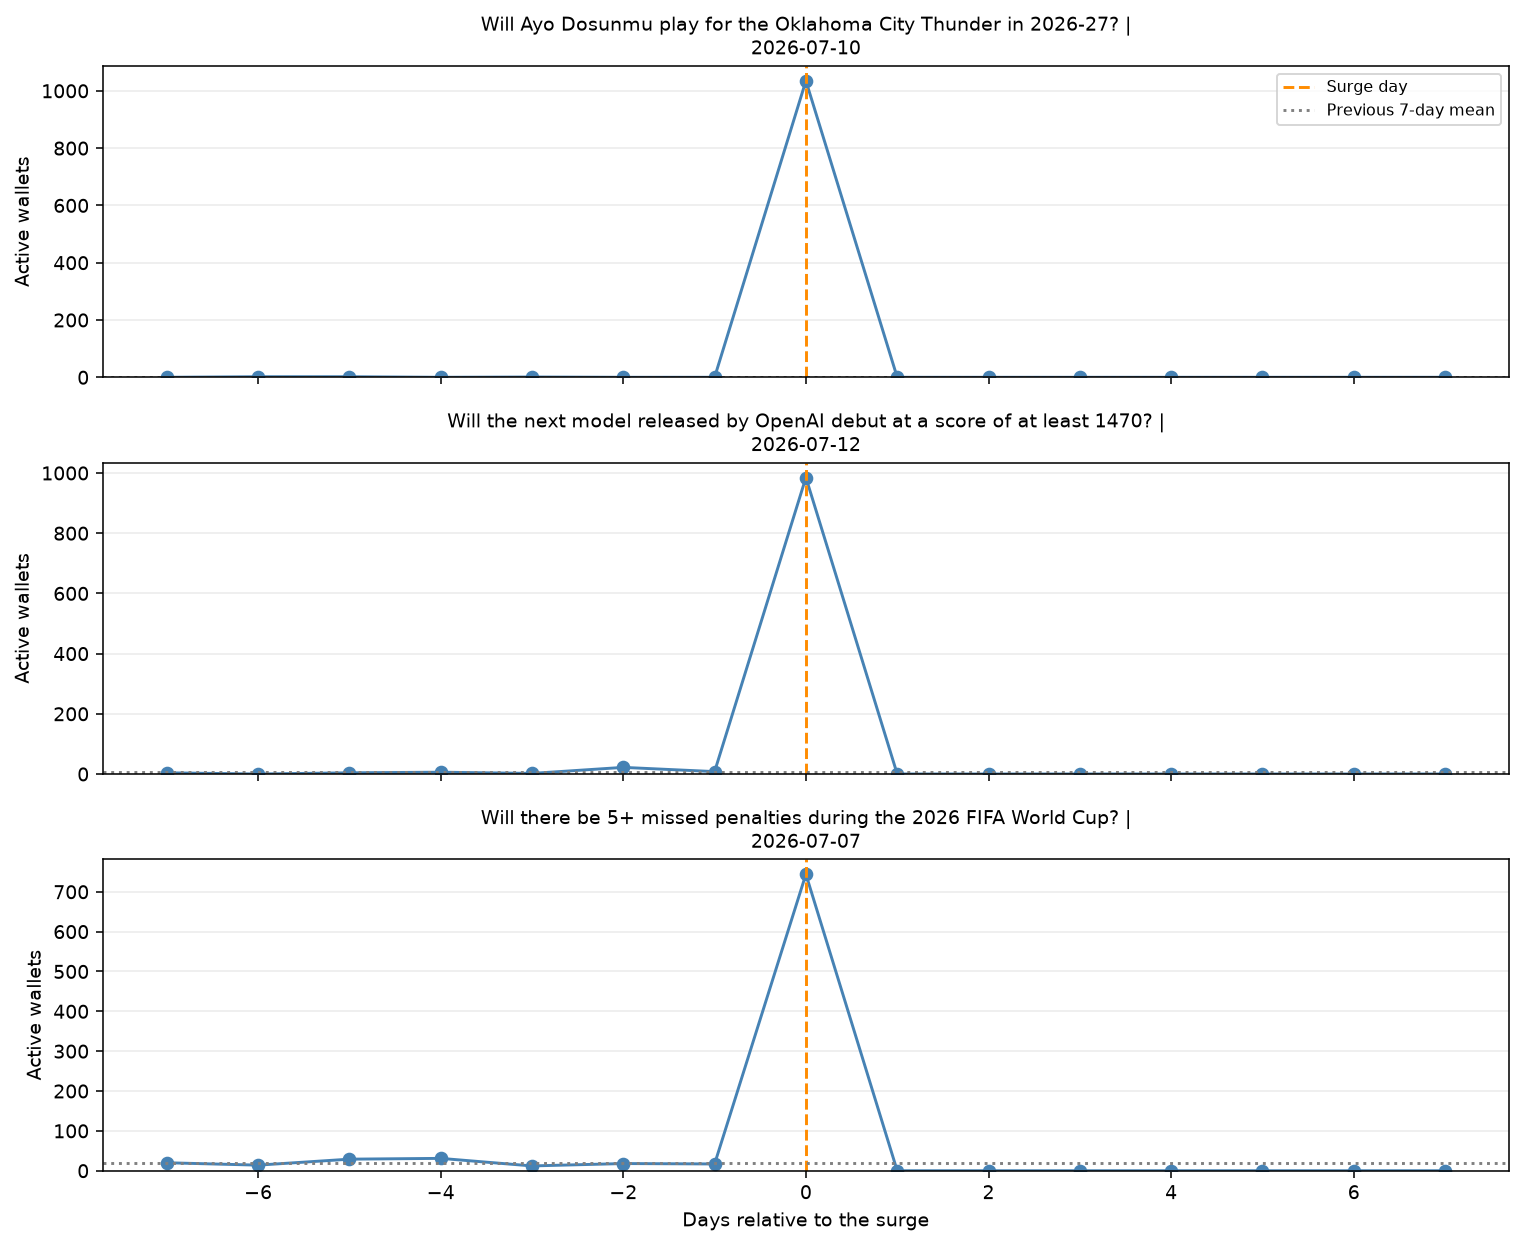

In [23]:
example_surges = surge_events.nlargest(3, "active_wallets")
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)

for i in range(3):
    event = example_surges.iloc[i]
    event_dates = pd.date_range(
        event["surge_day"] - pd.Timedelta(days=window_days), periods=2 * window_days + 1
    )
    counts = market_daily.loc[
        market_daily["market"] == event["market"]
    ].set_index("day")["active_wallets"].reindex(event_dates, fill_value=0)
    ax = axes[i]
    ax.plot(range(-window_days, window_days + 1), counts, marker="o", color="steelblue")
    ax.axvline(0, color="darkorange", linestyle="--", label="Surge day")
    ax.axhline(event["baseline_wallets"], color="gray", linestyle=":", label="Previous 7-day mean")
    ax.set_title(fill(f"{event['title']} | {event['surge_day']:%Y-%m-%d}", 75), fontsize=10)
    ax.set_ylabel("Active wallets")
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.25)

axes[0].legend(fontsize=8)
axes[-1].set_xlabel("Days relative to the surge")
fig.tight_layout()
plt.show()


The three largest candidates show one-day spikes followed by little or no trading. All three lack resolution records, so their stored end cutoffs do not confirm that trading remained possible afterward. These candidates need review before interpreting early participation or continued activity.
